In [1]:
from sklearn.model_selection import train_test_split


On commence ici avec un modèle de type **LSTM simple**, avec une seule couche cachée de 128 neurones. Cette couche LSTM permet au modèle de **lire une séquence de jours** un par un, comme un humain qui analyse une tendance sur plusieurs jours consécutifs. Le modèle ne contient **pas de dropout** pour l’instant (ou uniquement si on active plusieurs couches), et à la fin de la séquence, on passe la sortie du LSTM dans une **couche linéaire classique** (fully connected) qui prédit les 96 points de consommation du jour suivant.

Concrètement, chaque échantillon d'entrée (**X**) est une **matrice de taille (7, 113)** :
- **7** correspond à la fenêtre temporelle (donc les 7 derniers jours observés).
- **113** est le nombre total de features utilisés par jour : les 96 consommations + d'autres variables optionnelles (température, jours fériés, etc.).

Mais l'entraînement ne se fait pas échantillon par échantillon : on entraîne par **batchs** (par exemple, 32 blocs à la fois). Donc au total, chaque batch a une forme **(32, 7, 113)**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_squared_error, r2_score
import joblib

class LSTMEDF(nn.Module):
    def __init__(self, input_size, output_size=96, hidden_size=128, num_layers=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)          # out: (batch, seq_len, hidden_size)
        out = out[:, -1, :]            # on garde la dernière sortie temporelle
        out = self.fc(out)             # prédiction finale (batch, output_size)
        return out

class LSTMTrainer:
    def __init__(self, model, loss_fn=None, optimizer_class=None, lr=1e-3, verbose=True):
        self.model = model
        self.loss_fn = loss_fn or torch.nn.MSELoss()
        self.optimizer = (optimizer_class or torch.optim.Adam)(self.model.parameters(), lr=lr)
        self.verbose = verbose
        self.train_losses = []

    def fit(self, X_train, y_train, n_epochs=20, batch_size=32, verbose_every=1):
        self.model.train()
        dataset = torch.utils.data.TensorDataset(
            torch.tensor(X_train, dtype=torch.float32),
            torch.tensor(y_train, dtype=torch.float32)
        )
        loader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

        for epoch in range(1, n_epochs + 1):
            total_loss = 0.0
            for xb, yb in loader:
                self.optimizer.zero_grad()
                preds = self.model(xb)
                loss = self.loss_fn(preds, yb)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()
            avg_loss = total_loss / len(loader)
            self.train_losses.append(avg_loss)

            if self.verbose and epoch % verbose_every == 0:
                print(f"[Epoch {epoch}/{n_epochs}] Loss: {avg_loss:.4f}")

    def predict(self, X):
        self.model.eval()
        with torch.no_grad():
            X_tensor = torch.tensor(X, dtype=torch.float32)
            preds = self.model(X_tensor).numpy()
        return preds

    def evaluate(self, X_test, y_test, scaling_value=1.0):
        from sklearn.metrics import r2_score, mean_squared_error
        y_pred = self.predict(X_test)
        r2 = r2_score(y_test, y_pred)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        if self.verbose:
            print("Evaluation results:")
            print(f"  R²    : {r2:.4f}")
            print(f"  RMSE  : {rmse:.4f} (scaled: {rmse * scaling_value:.2f})")
        return {"r2": r2, "rmse": rmse}

    def save(self, path):
        torch.save(self.model.state_dict(), path)
        if self.verbose:
            print(f"Model saved to {path}")

    def plot_predictions(self, X_test, y_test, n_days=3, random_seed=None, scaling_value=1):
        """
        Plot predicted vs true consumption curves for N random days.
        """
        if random_seed is not None:
            np.random.seed(random_seed)

        indexes = np.random.choice(len(X_test), size=n_days, replace=False)
        y_pred = self.predict(X_test[indexes]) * scaling_value
        y_true = y_test[indexes] * scaling_value

        for i in range(n_days):
            plt.figure(figsize=(10, 4))
            plt.plot(y_true[i], label="True", linewidth=2)
            plt.plot(y_pred[i], label="Predicted", linestyle='--')
            plt.title(f"Prediction vs True Consumption - Sample {indexes[i]}")
            plt.xlabel("15-minute interval")
            plt.ylabel("Consumption")
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()

def create_lstm_dataset(df, window_size=7, target_col_prefix="consommation_", 
                        extra_feature_cols=None, target_known_cols=None, date_col = 'Date'):
    """
    Create a dataset for LSTM training using a sliding window over daily data.

    Each sample includes:
    - For the past `window_size` days:
        - Number points consumption vector
        - Optionally, extra features
        - Optionally, known-ahead information from the target day
    - The target is the numberpoints consumption vector of the next day.

    Parameters:
    - df: pandas DataFrame with one row per day
    - window_size: number of past days used as input
    - target_col_prefix: prefix to identify consumption columns
    - extra_feature_cols: list of additional columns to include for each past day
    - target_known_cols: list of known-ahead columns to replicate across each day in the sequence
    - date_col: name of the column containing the date

    Returns:
    - X: numpy array of shape (n_samples, window_size, n_features)
    - y: numpy array of shape (n_samples, nb_target_columns)
    - dates: list of lists → each sublist contains [date_J-window_size, ..., date_J] (window_size + 1 dates)
    """
    target_cols = [col for col in df.columns if col.startswith(target_col_prefix)]
    X_list, y_list, dates = [], [], []

    for i in range(window_size, len(df)):
        sequence = []
        dates_window = df.iloc[i - window_size:i + 1][date_col].tolist() # Include the target date
        
        # Get known-ahead features of the target day
        if target_known_cols:
            target_info = df.iloc[i][target_known_cols].values.tolist()
        else:
            target_info = []
        
        for j in range(i - window_size, i):
            row = df.iloc[j]

            row_features = []

            # Consumption values (mandatory)
            row_features.extend(row[target_cols].values.tolist())

            # Optional additional features
            if extra_feature_cols:
                row_features.extend(row[extra_feature_cols].values.tolist())

            # Replicate target day known-ahead info across the sequence
            row_features.extend(target_info)

            sequence.append(row_features)

        target_y = df.iloc[i][target_cols].values.tolist()

        X_list.append(sequence)
        y_list.append(target_y)
        dates.append(dates_window)

    X = np.array(X_list)
    y = np.array(y_list)
    
    return X, y, dates
    
def is_boolean_column(df, col):
    """
    Detect if a column behaves like a boolean.
    """
    unique_vals = set(df[col].dropna().unique())
    return unique_vals <= {0, 1} or unique_vals <= {True, False}

def encode_categorical(df, columns, start_at=0):
    """
    Encode categorical columns using simple integer mapping.
    """
    df = df.copy()
    mappings = {}

    for col in columns:
        if is_boolean_column(df, col):
            df[col] = df[col].astype(int)
        else:
            unique_vals = sorted(df[col].dropna().unique())
            map_dict = {val: i + start_at for i, val in enumerate(unique_vals)}
            df[col] = df[col].map(map_dict)
            mappings[col] = map_dict

    return df, mappings

def read_df(path):
    return pd.read_csv(path)

def rescale_consumption(df, factor=1, target_prefix="consommation_"):
    """
    Rescale consumption values by a fixed factor.
    """
    df = df.copy()
    cols = [col for col in df.columns if col.startswith(target_prefix)]
    df[cols] = df[cols] / factor
    return df

La fonction `create_lstm_dataset`|prend en entrée un DataFrame contenant des données journalières agrégées, avec notamment la consommation électrique décomposée en **96 points par jour** (toutes les 15 minutes), ainsi que d'autres variables comme la température, l’ensoleillement, ou encore des indicateurs temporels (mois, jour de la semaine, vacances…).

Elle construit un **dataset pour un modèle LSTM**, en utilisant une **fenêtre glissante** sur plusieurs jours consécutifs (par exemple les 7 derniers jours) afin de prédire la **courbe de consommation complète du jour suivant**.

Contrairement au modèle XGBoost qui utilise un flatten des données sur une seule ligne, ici on conserve **la structure séquentielle** :  
- Pour chaque exemple, on crée une **séquence de 7 jours** (ou autre selon le `window_size`)  
- Chaque jour est représenté par un vecteur de **features combinant** :
  - Les **96 points de consommation** de ce jour
  - D'autres variables associées à ce jour (comme la température ou l'ensoleillement), si on le souhaite

À cette séquence, on **ajoute en plus les informations connues à l'avance du jour cible (le jour J)** – par exemple : si c’est un jour férié, le mois, le jour de la semaine, etc.  
Plutôt que de les stocker à part, on **réplique ces informations sur chacun des 7 jours de la séquence**, ce qui permet au modèle de disposer à tout moment de la cible temporelle. Cette approche permet au LSTM de mieux contextualiser la séquence par rapport au jour qu’il est censé prédire.

À la fin, la fonction retourne :
- **X** : un tenseur 3D de forme `(n_samples, window_size, n_features)` contenant les séquences d’entrée pour le LSTM
- **y** : une matrice 2D de forme `(n_samples, 96)`, chaque ligne correspondant à la courbe de consommation du jour cible

In [3]:
# === 1. Load the dataset ===
df = read_df("training_data/train_data_inter_days.csv")

# === 2. Rescale conumption ===
df = rescale_consumption(df, factor=1)

# === 3. Encode categorical columns ===
cat_columns = ["month", "season", "weekday", "tempo"]
df_encoded, _ = encode_categorical(df, columns=cat_columns)

X, y, dates = create_lstm_dataset(
    df=df_encoded,
    window_size=7,
    target_col_prefix='consommation_',
    extra_feature_cols=None,
    target_known_cols=None,
    date_col='Date'
)

# === 4. Split train/test ===
X_train, X_test, y_train, y_test, dates_train, dates_test = train_test_split(
    X, y, dates, test_size=0.2, shuffle=False
)

# === 5. Initialize the model ===
input_size = X.shape[2]  # nombre de features par jour
model = LSTMEDF(input_size=input_size)

# === 6. Create Trainer ===
trainer = LSTMTrainer(model=model, verbose=True)

# === 7. Train the model ===
trainer.fit(X_train, y_train, n_epochs=50, batch_size=64)

# === 8. Evaluate ===
trainer.evaluate(X_test, y_test)

[Epoch 1/50] Loss: 3053626485.6216
[Epoch 2/50] Loss: 3050992079.5676
[Epoch 3/50] Loss: 3051764659.8919
[Epoch 4/50] Loss: 3054831560.6486
[Epoch 5/50] Loss: 3048465352.6486
[Epoch 6/50] Loss: 3048418096.4324
[Epoch 7/50] Loss: 3049164765.4054
[Epoch 8/50] Loss: 3049341799.7838
[Epoch 9/50] Loss: 3051553487.5676
[Epoch 10/50] Loss: 3053522971.6757
[Epoch 11/50] Loss: 3044722764.1081
[Epoch 12/50] Loss: 3050122364.5405
[Epoch 13/50] Loss: 3047908656.4324
[Epoch 14/50] Loss: 3054730357.6216
[Epoch 15/50] Loss: 3058978497.7297
[Epoch 16/50] Loss: 3048263513.9459
[Epoch 17/50] Loss: 3052078647.3514
[Epoch 18/50] Loss: 3049216242.1622
[Epoch 19/50] Loss: 3051176752.4324
[Epoch 20/50] Loss: 3053482060.1081
[Epoch 21/50] Loss: 3053453395.0270
[Epoch 22/50] Loss: 3047140739.4595
[Epoch 23/50] Loss: 3050528166.0541
[Epoch 24/50] Loss: 3051890162.1622
[Epoch 25/50] Loss: 3052447342.7027
[Epoch 26/50] Loss: 3050251174.0541
[Epoch 27/50] Loss: 3050121195.2432
[Epoch 28/50] Loss: 3049628256.8649
[

{'r2': -24.288190175138507, 'rmse': np.float64(52046.98927588331)}

In [5]:
y.shape

(2915, 96)

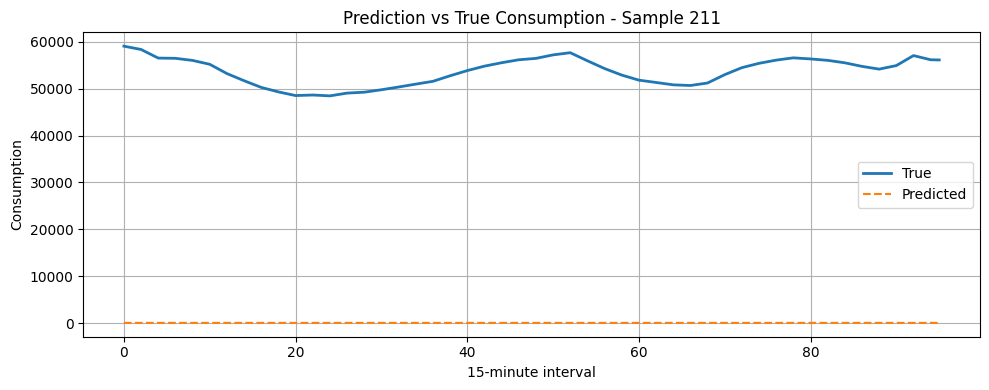

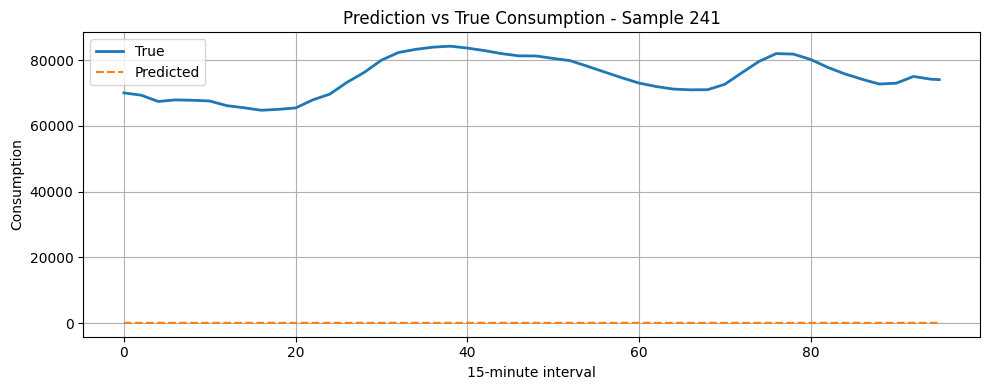

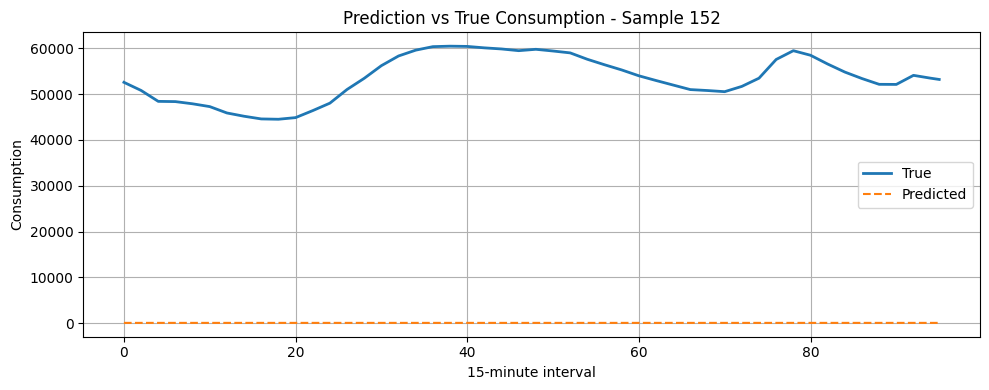

In [4]:
# === 9. Plot predictions (optional preview) ===
trainer.plot_predictions(X_test, y_test, n_days=3, scaling_value=1)